# Limitation 4 — A scene that moves

**Every window is taken at its own epoch. A companion that moves is somewhere else in each one. The images assume one static scene; the map assumes the lines meet at one point; the static fit assumes one position; the moving fit assumes a straight line at constant speed and a constant flux, and nothing else.**

Every limitation notebook has the same four parts. **The premise** states
what the atoms assume and shows the case that breaks it. Then **one section
per atom**, always in the same order, the two images of the windows, the map
of detections, the joint fit, each answering three questions: what does this
atom assume here, what does it return in this case, and does it warn you.
**The summary table** closes with the same columns every time: atom, effect,
alarm, remedy.

The case of this page: the control pair, 200 mas at position angle 110°, with the companion drifting at 0 to 30 mas/yr over 4.6 years of 80 windows whose epochs are paired with the directions at random; then a companion that accelerates, and one whose flux varies.

| block | task | calls | paper |
|---|---|---|---|
| 1 | the premise: a drifting companion's track and its along-scan residual | `ins.project_al` | Sects. 4.1–4.2, Eqs. 14–15 |
| 2 | the two images of a drifting companion | `radon.filtered_backprojection`, `radon.faststack` | App. C.2, Eq. C.3 (the static images) |
| 3 | the map of detections pooled without a motion correction | `bp.map_peak`, `bp.peak_consistency` | Sect. 3.3, Eq. 13; Sect. 4.2, Eq. 17 |
| 4 | the static and the moving joint fit; an acceleration; a varying flux | `joint.fit_joint` | Sect. 4.3, Eq. 18; Sect. 4.5 |

Every scanlib call carries the name of its module (`joint.fit_joint`); the first code cell lists the modules.

**The series.** The three images and the fit are in [`../00_three_images_and_fit.ipynb`](../00_three_images_and_fit.ipynb). The limitations: [1 — the finite window](01_finite_window.ipynb), [2 — the scan law](02_scan_law.ipynb), [3 — one line, two lines, three](03_few_lines.ipynb), this page, [5 — the blend](05_blend.ipynb), [6 — errors of the model, and the noise](06_model_errors.ipynb).

**Symbols and units** are defined once for the package and every notebook in [`docs/conventions.md`](../../../docs/conventions.md). This page uses ψ, η, τ, μ and a, σ_η and the detections, the two images, the map and its width, θ, the Fisher σ, the pull, and χ²/dof.

In [1]:
# the imports: numpy, matplotlib, and the scanlib modules; every scanlib call below carries its module's name
import numpy as np
import matplotlib.pyplot as plt

from scanlib import instrument as ins      # the instrument: sampling, LSF, the along-scan projection (Eq. 9)
from scanlib import simulation as sim      # synthetic scenes and their windows
from scanlib import backprojection as bp   # the triangulation map and its peak
from scanlib import radon                  # the inverse Radon transform and faststack
from scanlib import joint                  # the joint fit of all windows, and its helpers

In [2]:
# the paper's figure style: font 10, ticks 9 and inward, thin axes; grays first, one accent
plt.rcParams.update({"font.size": 10.0, "axes.linewidth": 0.5, "xtick.labelsize": 9.0, "ytick.labelsize": 9.0,
                     "xtick.direction": "in", "ytick.direction": "in", "legend.frameon": False, "legend.fontsize": 7.5})
ACCENT = "tomato"                                          # the one accent
ACCENT_2 = "dodgerblue"                                    # a second highlight (the track on the images)
# the markers: each name below in capitals with dict(...) is a table of the keywords that ax.scatter takes for
# one kind of point
TRUTH = dict(marker="*", s=150, facecolor="white", edgecolor="k", lw=0.8, zorder=7)   # the truth
SEED = dict(marker="o", s=60, facecolor="none", edgecolor=ACCENT, lw=1.1, zorder=6)  # a starting point (the map's peak)
PRIMARY = dict(marker="+", s=110, color="k", lw=1.4, zorder=6)                       # the primary
# the labels of the two sky axes
EAST = r"$\Delta\alpha^{*}$  [mas]   (East $\leftarrow$)"
NORTH = r"$\Delta\delta$  [mas]"


def letter(ax, label, text=""):
    """Write a panel's letter, bold, inside the panel's top-left corner, and a few words after it.

    Inputs
        ax      the panel (a matplotlib Axes)
        label   the panel's letter, for example "a"
        text    the words after the letter (default: none)
    Returns nothing: the letter and the words are drawn on ax, on a white box that dims what is under them."""
    white_box = dict(fc="white", ec="none", pad=1.0, alpha=0.8)
    ax.text(0.04, 0.96, rf"$\bf{{({label})}}$ " + text, transform=ax.transAxes, va="top", ha="left", fontsize=9,
            bbox=white_box)

In [3]:
# the toy instrument, the noise, the pair's position angle and fluxes, the two sets of scan directions, and the
# sky grid of every image
FWHM = 100.0                                 # the LSF's full width at half maximum [mas]
# The instrument, defined once: 18 samples 59 mas apart, a Gaussian LSF of
# that FWHM, and the trial positions of the per-window reduction.
inst = ins.Instrument.gaussian(fwhm_mas=FWHM, pitch_mas=59.0, n_samples=18)
grid = inst.sample_grid_mas                  # sample centers along the scan [mas]
pitch = grid[1] - grid[0]                    # the distance between two neighboring samples: 59 mas
sigma_lsf = FWHM / (2.0 * np.sqrt(2.0 * np.log(2.0)))   # LSF sigma [mas], for the formulas
sigma_noise = 10.0                           # the noise sigma of one sample; the primary's total flux is 100 sigma
pa = np.deg2rad(110.0)                       # the pair's position angle [rad], counter-clockwise from north
flux = np.array([1000.0, 200.0])             # the fluxes of the primary and of the companion, in the windows' units
EVEN = np.linspace(0.0, np.pi, 80, endpoint=False) + 0.01     # 80 even directions [rad]
# ref: the reference cases of the package's tests, a table from a case's name to its array; two of its inputs
# are used here
ref = np.load("../../../tests/reference/reference_cases.npz")
GAIA = ref["static_pair/inputs/psi"]                           # the Gaia forecast's 40 scan angles [rad]
GAIA_TAU = ref["moving_pair/inputs/tau"]                       # and epochs [yr]
half = 400.0                                 # the sky grid of every image: half the side of the square [mas]
step = 4.0                                   # and the size of one pixel [mas]
# degrees of freedom of a static two-source fit on 80 windows: 80 x 18 samples, minus the companion's two
# coordinates and the two fluxes
DOF = EVEN.size * grid.size - 4

In [4]:
# helper: the companion's sky offset at a separation on the pair axis
def pair(rho):
    """The companion's sky offset at a separation on the pair axis (the direction of position angle pa).

    Inputs
        rho   the companion's separation from the primary [mas]
    Returns
        the companion's (dra*, ddec) [mas] from the primary, an array of two numbers"""
    pair_axis = np.array([np.sin(pa), np.cos(pa)])            # the unit vector of the pair axis, (dra*, ddec)
    return rho * pair_axis

In [5]:
# helper: the windows of a scene, noise-free or noisy (ins.render_window, sim.simulate_window)
def windows_of(theta, psi, flux=flux, tau=None, rng=None, present=None, eta0=None, inst=inst):
    """The windows of a scene, one per scan: noise-free (a formula), or with one draw of noise each.

    Inputs
        theta     the companions' parameters, one flat array: (dra*, ddec) [mas] per companion for a static scene,
                  (dra*, ddec [mas], mu_alpha*, mu_delta [mas/yr]) per companion for a moving one. The primary is
                  at the origin and has no entry
        psi       the scan angle of each of the J windows [rad]
        flux      the flux of each of the K sources, in the windows' units, the primary first
        tau       the epoch of each window [yr] for a moving scene (None: a static scene)
        rng       the random generator of the noise, of sigma_noise per sample (None: noise-free windows)
        present   J rows of K booleans: which source is in which window (None: every source in every window)
        eta0      the zero point of each window [mas] (None: every zero point is 0)
        inst      the instrument that renders the windows (default: the page's instrument)
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of every source in every window [mas]: one row per window, one column per
    # source, the primary first. Each window's zero point is subtracted from its row; [:, None] turns the J zero
    # points into a column, so that row j gets eta0[j]
    eta = joint.scene_positions_al(theta, psi, tau)
    if eta0 is not None:
        eta = eta - np.asarray(eta0)[:, None]

    # step 2, one window per scan; j counts the windows
    windows = []
    for j, eta_j in enumerate(eta):
        # the fluxes in window j: present[j] holds one True or False per source, and a source that is not in
        # the window gets flux 0
        if present is None:
            flux_j = flux
        else:
            flux_j = flux * present[j]
        # the samples of window j: the noise-free model, or the model plus one draw of noise from rng
        if rng is None:
            window = ins.render_window(eta_j, flux_j, inst)
        else:
            window = sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise)
        windows.append(window)
    return np.array(windows)

In [6]:
# helper, a stand-in for the per-window reduction: the Fisher error of each companion's position in one window
def sigma_eta(eta, flux=flux, sigma_noise=sigma_noise):
    """The Fisher error of each companion's along-scan position in one window, with every flux free. It is a
    formula, not a fit: it stands in for the error that the per-window reduction would report.

    Inputs
        eta           the along-scan position of each of the K sources in the window [mas], the primary first
        flux          the flux of each of the K sources, in the windows' units, the primary first
        sigma_noise   the noise sigma of one sample, in the windows' units
    Returns
        the 1-sigma error of each companion's position [mas], K - 1 numbers (the primary's position is not a
        parameter); every one is infinite where the Fisher matrix is singular"""
    # step 1, the model of the window. columns[:, k] is the window of source k alone at flux 1, one number per
    # sample; derivatives[:, k] is the derivative of that column with respect to the position of source k [1/mas]
    columns = inst.design_columns(eta)
    derivatives = inst.design_jacobian(eta)

    # step 2, the derivative of the window with respect to every parameter, one column each: first the
    # companions' positions ([:, 1:] omits the primary's column and flux[1:] the primary's flux), then the K fluxes
    jacobian = np.column_stack([derivatives[:, 1:] * flux[1:], columns])

    # step 3, the Fisher matrix for Gaussian noise of known sigma. Where its condition number is above 1e12 it
    # cannot be inverted safely: the companions' positions are then not measured in this window
    fisher = jacobian.T @ jacobian / sigma_noise ** 2
    n_companions = eta.size - 1
    if np.linalg.cond(fisher) > 1e12:
        return np.full(n_companions, np.inf)

    # step 4, the errors: the square roots of the diagonal of the inverse. [:n_companions] keeps the positions'
    # entries and omits the fluxes'
    covariance = np.linalg.inv(fisher)
    return np.sqrt(np.diag(covariance)[:n_companions])

In [7]:
# helper, the stand-in's detections: the truth plus one draw of that error, where the error is below 30 mas
def detections(theta, psi, flux=flux, tau=None, sigma_max=30.0, rng=None, present=None):
    """The teaching detections of a scene, a stand-in for the per-window reduction: no window is simulated and no
    window is fitted. A detection is a companion's true along-scan position in a window plus one Gaussian draw of
    its Fisher error there (sigma_eta, at the page's noise sigma_noise).

    Inputs
        theta       the companions' parameters, one flat array, as in windows_of
        psi         the scan angle of each of the J windows [rad]
        flux        the flux of each of the K sources, in the windows' units, the primary first
        tau         the epoch of each window [yr] for a moving scene (None: a static scene)
        sigma_max   a companion gives a detection in a window only where its Fisher error is finite and at most
                    this [mas]
        rng         the random generator of the draws (None: a new generator of seed 8 at every call)
        present     J rows of K booleans: which source is in which window (None: every source in every window);
                    a companion gives no detection in a window that it is not in
    Returns three arrays, one entry per detection
        psi     the scan angle of the detection's window [rad]
        eta     the detected along-scan position [mas]: the truth plus the draw
        sigma   the 1-sigma error of that position [mas]"""
    # step 1, the generator of the detections' errors. The default is a new generator of seed 8 at every call,
    # so two calls for the same scene give the same draws (why 8: not stated)
    if rng is None:
        rng_detections = np.random.default_rng(8)
    else:
        rng_detections = rng

    # step 2, the true along-scan position of every source in every window [mas]: row j is window j, column 0
    # the primary
    eta_true = joint.scene_positions_al(theta, psi, tau)

    # step 3, one detection per window and companion that passes the two tests. j counts the windows; c counts
    # the sources of a window from 1, because source 0 is the primary and gives no detection
    detected_psi = []
    detected_eta = []
    detected_sigma = []
    for j, psi_j in enumerate(psi):
        eta_j = eta_true[j]
        sigma_j = sigma_eta(eta_j, flux)                       # the Fisher error of each companion in window j
        for c in range(1, eta_j.size):
            sigma = sigma_j[c - 1]                             # sigma_j has no entry for the primary
            if present is not None and not present[j, c]:
                continue
            if np.isfinite(sigma) and sigma <= sigma_max:
                error_draw = rng_detections.normal(0.0, sigma)
                detected_psi.append(psi_j)
                detected_eta.append(eta_j[c] + error_draw)
                detected_sigma.append(sigma)
    return np.array(detected_psi), np.array(detected_eta), np.array(detected_sigma)

In [8]:
# helper: the points of a covariance ellipse
def ellipse(cov, center, n_sigma=1.0):
    """The outline of a covariance ellipse on the sky, as points to plot.

    Inputs
        cov       the 2 x 2 covariance of a position (dra*, ddec) [mas^2]
        center    the center of the ellipse, (dra*, ddec) [mas]
        n_sigma   the size of the ellipse, its Mahalanobis radius (1: the 1-sigma ellipse)
    Returns
        200 points around the ellipse, one row (dra*, ddec) [mas] per point; the last point repeats the first"""
    # step 1, the ellipse's axes: the eigenvalues are the variances along them [mas^2], the columns of
    # eigenvectors are their directions
    eigenvalues, eigenvectors = np.linalg.eigh(cov)

    # step 2, the unit circle at 200 angles around the full turn: row 0 holds the cosines, row 1 the sines
    angles = np.linspace(0, 2 * np.pi, 200)
    unit_circle = np.vstack([np.cos(angles), np.sin(angles)])

    # step 3, the circle stretched to the ellipse's semi-axes ([:, None] makes them a column: one factor per
    # row of the circle), turned to the axes' directions, and moved to the center. .T gives one row per point
    semi_axes = n_sigma * np.sqrt(eigenvalues)[:, None]
    stretched = semi_axes * unit_circle
    turned = eigenvectors @ stretched
    return turned.T + center

In [9]:
# helper: draw one sky image or map, east to the left, with the sources marked
def show(ax, image, axis, title, marks=None, **imshow_options):
    """Draw one sky image or map, east to the left, with the sources marked by plus signs.

    Inputs
        ax               the panel (a matplotlib Axes)
        image            the image or the map, M rows of M pixels: the rows are ddec, the columns dra*
        axis             the sky coordinate of the M rows, and of the M columns [mas]
        title            the panel's title
        marks            the sources to mark, one row (dra*, ddec) [mas] each (None: the primary at the origin and
                         the companion of this page, the global theta)
        imshow_options   keywords for ax.imshow, for example vmax, the value drawn black
    Returns
        the drawn image (matplotlib's AxesImage)"""
    # step 1, the defaults of the picture, used where the call names no other: white at 0 and black at the
    # highest value, and every pixel drawn as it is (no smoothing)
    imshow_options.setdefault("cmap", "gray_r")
    imshow_options.setdefault("vmin", 0.0)
    imshow_options.setdefault("interpolation", "nearest")

    # step 2, the picture: row 0 at the bottom (north up); axis[0] and axis[-1] are the first and the last
    # coordinate, given as the picture's left and right, and bottom and top
    extent = (axis[0], axis[-1], axis[0], axis[-1])
    drawn_image = ax.imshow(image, origin="lower", extent=extent, **imshow_options)

    # step 3, the plus signs: column 0 of the marks is dra*, column 1 is ddec
    if marks is None:
        marked_sources = np.vstack([[0.0, 0.0], theta])
    else:
        marked_sources = marks
    ax.scatter(marked_sources[:, 0], marked_sources[:, 1], marker="+", s=70, color=ACCENT, lw=1.1, zorder=6)

    # step 4, the title, the label, and the direction of the horizontal axis
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(EAST)
    ax.set_aspect("equal")
    ax.set_xlim(axis[-1], axis[0])                               # east to the left
    return drawn_image

In [10]:
# helper: one printed line that compares a fit with the truth
def report(name, fit, truth, dof):
    """Print one line that compares a joint fit with the truth.

    Inputs
        name    the words that open the line
        fit     the result of joint.fit_joint, a table from a name to a value. Four entries are read:
                fit["theta"] the fitted parameters, fit["sigma_theta"] their Fisher 1-sigma errors, fit["flux"]
                the fitted fluxes (the primary first) and fit["chi2"]
        truth   the true parameters, in the order and the units of fit["theta"]
        dof     the degrees of freedom of the fit
    Returns nothing. The printed line holds: fit - truth for every parameter; the pulls (fit - truth over the
    Fisher sigma); the fluxes of the first two sources; chi2 / dof."""
    difference = fit["theta"] - np.asarray(truth)
    pulls = difference / fit["sigma_theta"]
    # the numbers as text, joined by commas (a short comprehension: one piece of text per parameter)
    difference_text = ", ".join(f"{value:6.2f}" for value in difference)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    primary_flux = fit["flux"][0]
    companion_flux = fit["flux"][1]
    chi2_per_dof = fit["chi2"] / dof
    print(f"{name:40s} fit − truth ({difference_text})   pulls ({pulls_text})"
          f"   fluxes {primary_flux:.0f}, {companion_flux:.0f}   chi2/dof {chi2_per_dof:.2f}")

In [11]:
# the case of this page: the control pair at 200 mas; the 80 even directions get epochs over 4.6 years,
# shuffled against the angles so that angle and epoch are independent (limitation notebook 2, section 4)
theta = pair(200.0)                                           # the companion at the reference epoch [mas]
# rng_epochs: seed 0, the one random order of the epochs against the scan angles
rng_epochs = np.random.default_rng(0)
epochs_in_order = np.linspace(-2.3, 2.3, EVEN.size)           # 80 even epochs from -2.3 to 2.3 yr
TAU = rng_epochs.permutation(epochs_in_order)                 # the epoch of each window [yr]
# degrees of freedom of a moving two-source fit: 80 x 18 samples, minus the companion's position and proper
# motion (four numbers) and the two fluxes
DOF_MOVING = EVEN.size * grid.size - 6

In [12]:
# helper of this page: the companion's sky position in every window, for a drift and an acceleration
def track_of(mu, acc=0.0, acc_direction=(0.6, 0.8)):
    """The companion's sky position in every window, for a constant proper motion and a constant acceleration:
    theta + mu tau + (acc / 2) tau^2 acc_direction, with tau the page's epochs TAU.

    Inputs
        mu              the proper motion (mu_alpha*, mu_delta) [mas/yr]
        acc             the size of the acceleration [mas/yr^2] (default: none)
        acc_direction   the unit vector (dra*, ddec) of the acceleration
    Returns
        the track: one row (dra*, ddec) [mas] per window, J rows"""
    # np.outer(a, b) has one row per epoch: row j is a[j] times the two numbers of b
    drift = np.outer(TAU, mu)
    curvature = 0.5 * acc * np.outer(TAU ** 2, acc_direction)
    return theta + drift + curvature

In [13]:
# helper of this page: the noisy windows of a companion on a given track (sim.simulate_window)
def windows_of_track(track, flux=flux, rng=None):
    """The noisy windows of the primary and of a companion on a given track, on the 80 even directions. The
    primary is at the origin in every window.

    Inputs
        track   the companion's (dra*, ddec) [mas] in each window, J rows of two numbers
        flux    the fluxes (primary, companion) in the windows' units: two numbers, the same in every window, or
                J rows of two numbers, one row per window
        rng     the random generator of the noise, of sigma_noise per sample; the call must give one
    Returns
        the windows, an array of J rows of N samples, flux per sample"""
    # step 1, the along-scan position of the two sources in every window [mas]: column 0 the primary (zero),
    # column 1 the companion, eta = dra* sin(psi) + ddec cos(psi) with track[:, 0] its dra* and track[:, 1] its ddec
    eta_primary = np.zeros(EVEN.size)
    eta_companion = track[:, 0] * np.sin(EVEN) + track[:, 1] * np.cos(EVEN)
    eta = np.column_stack([eta_primary, eta_companion])

    # step 2, one pair of fluxes per window: a single pair (np.ndim is 1) is repeated for every window
    if np.ndim(flux) == 1:
        flux_per_window = np.broadcast_to(flux, (EVEN.size, 2))
    else:
        flux_per_window = flux

    # step 3, one noisy window per scan, in the order of the windows: rng gives the noise of window 0 first
    windows = []
    for eta_j, flux_j in zip(eta, flux_per_window):
        windows.append(sim.simulate_window(eta_j, flux_j, inst, rng, sigma_noise))
    return np.array(windows)

## 1. The premise, and the case that breaks it

*Paper: Sects. 4.1 and 4.2; Eq. 14 (linear motion), Eq. 15 (the sinogram of a moving source).*

In window j, taken at epoch τⱼ, a companion at (Δα\*, Δδ) at the reference
epoch and drifting at μ appears at η = (Δα\* + μα\* τⱼ) sin ψⱼ + (Δδ +
μδ τⱼ) cos ψⱼ. Over the campaign a drift of 30 mas/yr moves it 140 mas,
more than a FWHM. The figure shows the companion's track on the sky (a) and its
along-scan position in each window against the static prediction (b): the
residual that every static atom has to live with. It grows with the
epoch's distance from the reference epoch, to about 60 mas at the ends,
and its sign at a given epoch depends on the scan angle, because a window
measures only the drift's projection on its scan direction; that is the
scatter about the trend.

In [14]:
# the track of a companion drifting 30 mas/yr, and its along-scan position in each window: moving (from the
# track; column 0 is dra*, column 1 is ddec) and static (*theta unpacks the reference-epoch dra*, ddec)
DRIFT_DIRECTION = np.array([0.8, -0.6])                       # the unit vector (dra*, ddec) of every drift of this page
mu_30 = 30.0 * DRIFT_DIRECTION                                # the proper motion of 30 mas/yr [mas/yr]
track = track_of(mu_30)
eta_moving = track[:, 0] * np.sin(EVEN) + track[:, 1] * np.cos(EVEN)
eta_static = ins.project_al(*theta, EVEN)

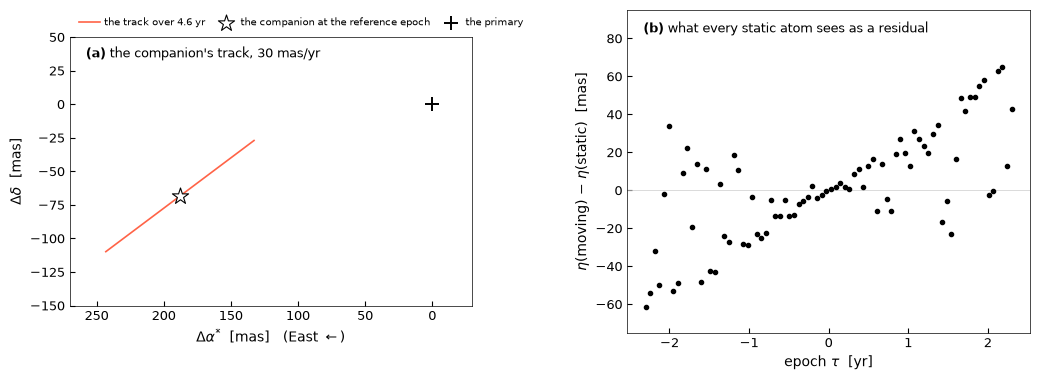

the drift over the span: 138 mas, 1.4 FWHM


In [15]:
# Figure 1: (a) the track on the sky, with the primary (plus) and the companion at the reference epoch (star);
# (b) the moving minus the static along-scan position, against the epoch
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9))
# step 1, (a): the track, drawn in the order of time. `order` holds the windows' indices sorted by epoch;
# track[order, 0] is dra* in that order, track[order, 1] is ddec
order = np.argsort(TAU)
axes[0].plot(track[order, 0], track[order, 1], color=ACCENT, lw=1.2, label="the track over 4.6 yr")
axes[0].scatter(*theta, **TRUTH, label="the companion at the reference epoch")
axes[0].scatter(0, 0, **PRIMARY, label="the primary")
axes[0].set(xlabel=EAST, ylabel=NORTH, xlim=(270, -30), ylim=(-150, 50), aspect="equal")
axes[0].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3, columnspacing=1.0, handletextpad=0.4)
letter(axes[0], "a", "the companion's track, 30 mas/yr")

# step 2, (b): what the motion adds to the along-scan position of the companion in each window
axes[1].axhline(0, color="0.8", lw=0.5)
axes[1].plot(TAU, eta_moving - eta_static, "o", color="k", ms=3)
axes[1].set(xlabel=r"epoch $\tau$  [yr]", ylabel=r"$\eta$(moving) $-$ $\eta$(static)  [mas]", ylim=(-75, 95))
letter(axes[1], "b", "what every static atom sees as a residual")
plt.tight_layout()
plt.show()
# the length of the track [mas]: the size of the proper motion (*mu_30 unpacks its two numbers) times the span
# of the epochs
drift_over_span = np.hypot(*mu_30) * (TAU.max() - TAU.min())
print(f"the drift over the span: {drift_over_span:.0f} mas, {drift_over_span / FWHM:.1f} FWHM")

## 2. The two images

*Paper: App. C.2, Eq. C.3 (the two images of a static scene); their smear by a motion is not in the paper; it is here because the images take all windows as one scene.*

**What they assume.** One scene: the inverse Radon transform inverts the
projections of one object, faststack stacks the samples of one object.

**What they return.** A drifting companion is somewhere else in every
window, and each image spreads it along its track. Where the drift exceeds a
FWHM its peak drops. faststack read along a trial motion, Harrison's
dynamical channel, would restore it and is not in this package.

**The figure.** The two images of the companion drifting 30 mas/yr; the plus signs mark the primary and the
companion's position at the reference epoch, the line is the track.

**Do they warn.** No. The smear looks like an extended source.

In [16]:
# the windows of the companion drifting 30 mas/yr, and their two images. radon.faststack returns (image,
# variance, number of samples, axis); `_` drops the last three. `ends` holds the two ends of the track
rng_noise = np.random.default_rng(6)                          # seed 6: the noise of these windows
wins_30 = windows_of_track(track, rng=rng_noise)
image, axis = radon.filtered_backprojection(EVEN, wins_30, inst, half, step)
stack, _, _, _ = radon.faststack(EVEN, wins_30, inst, half, step)
# the companion's position at the first and at the last epoch: one row (dra*, ddec) [mas] each
ends = theta + np.outer([TAU.min(), TAU.max()], mu_30)

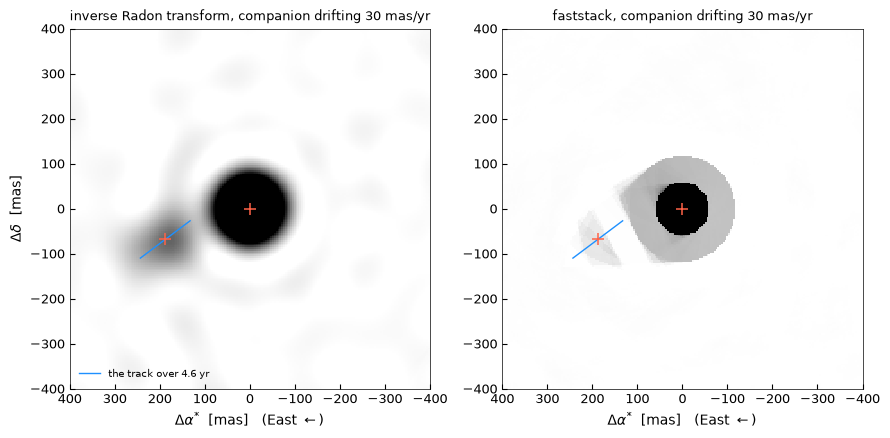

In [17]:
# Figure 2: the two images; the plus signs mark the primary and the companion at the reference epoch, the line
# is the track
fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.6))
# one row per panel: the panel, its image, the image's name, and the value drawn black
PANELS = ((axes[0], image, "inverse Radon transform", 0.02), (axes[1], stack, "faststack", 250))
for ax, sky_image, name, vmax in PANELS:
    show(ax, sky_image, axis, f"{name}, companion drifting 30 mas/yr", vmax=vmax)
    ax.plot(ends[:, 0], ends[:, 1], color=ACCENT_2, lw=1, label="the track over 4.6 yr")
axes[0].set_ylabel(NORTH)
axes[0].legend(loc="lower left")
plt.tight_layout()
plt.show()

## 3. The map of detections

*Paper: Sect. 3.3, Eq. 13 (the map of a static scene); Sect. 4.2, Eq. 17 (the motion-corrected map, the remedy).*

**What it assumes.** That every line passes through one point. A detection
of a moving companion is a line through its position at that window's
epoch, and those positions lie along the track.

**What it returns.** The lines of a drifting companion do not meet at one
point; they envelope the track. For 5 mas/yr the crossing is still one
peak, displaced and broadened; for 30 mas/yr the map shows a ridge along
the track and its peak sits where the lines happen to bunch. A pipeline
fixes this by shifting each detection to a common epoch under a trial
motion, which is dev's job, not this package's.

**The figure.** Three maps of the same pair, for a drift of 0, 5 and
30 mas/yr; the plus signs are the primary and the companion's position
at the reference epoch, the open circle the peak. At 0 mas/yr all 76 lines meet
at one point. At 5 mas/yr they still meet within 3 mas, the peak's width
grows from 6.8 to 8.4 mas, and 72 of the 76 lines pass through it. At
30 mas/yr the lines spread along the track, drawn as a line, into a tangle:
the peak is 32 mas from the reference-epoch position, 20 mas wide, and
only 39 of the 76 lines pass through it.

**Does it warn.** Partly: the width `bp.map_peak` reports grows, and
`bp.peak_consistency` drops the lines that miss.

drift    0 mas/yr: 76 lines; peak (187, -69), 1 mas from the reference-epoch position, width 6.8 mas; 76 lines pass through it
drift    5 mas/yr: 76 lines; peak (189, -71), 3 mas from the reference-epoch position, width 8.4 mas; 72 lines pass through it
drift   30 mas/yr: 76 lines; peak (212, -90), 32 mas from the reference-epoch position, width 19.7 mas; 39 lines pass through it


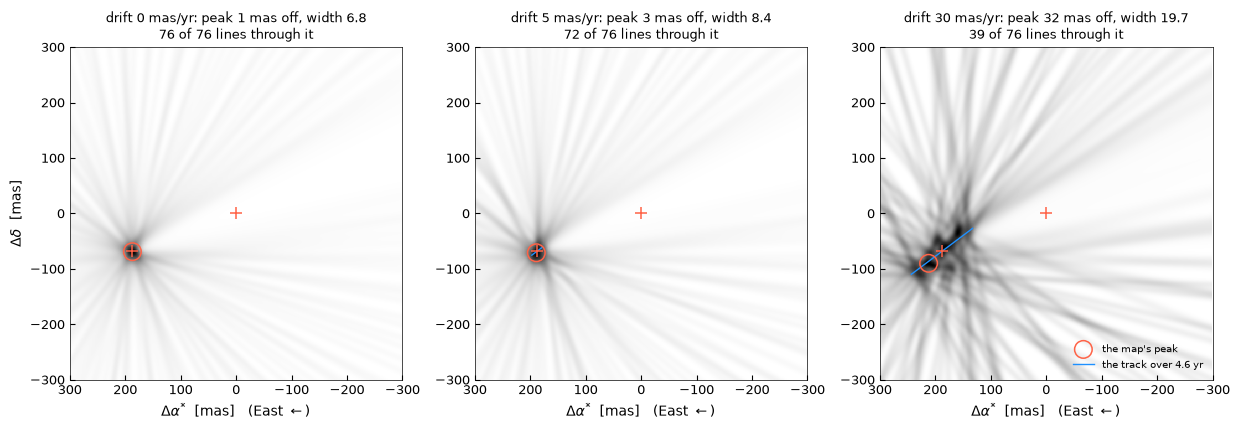

In [18]:
# Figure 3: the map of the detections of a companion drifting 0, 5 and 30 mas/yr, pooled without any motion
# correction. np.r_[theta, mu] joins the position and the proper motion into the flat vector of a moving
# companion; bp.peak_consistency returns (keep, distance) and `_` drops the distances; keep is a mask of the
# lines that pass through the peak
fig, axes = plt.subplots(1, 3, figsize=(12.5, 4.6))
for ax, rate in zip(axes, (0.0, 5.0, 30.0)):
    # step 1, the teaching detections of the moving companion (the stand-in, not a reduction of windows): the
    # true along-scan position at each window's epoch plus one draw of its error
    mu = rate * DRIFT_DIRECTION                               # the proper motion (mu_alpha*, mu_delta) [mas/yr]
    theta_moving = np.r_[theta, mu]
    d_psi, d_eta, d_sigma = detections(theta_moving, EVEN, tau=TAU)

    # step 2, the map of those detections as if the companion did not move: its peak, its width, the map and
    # the map's axis; then the lines that pass through the peak
    peak, width, sky_map, map_axis = bp.map_peak(d_psi, d_eta, d_sigma, 300.0, 1.0)
    keep, _ = bp.peak_consistency(d_psi, d_eta, d_sigma, peak, width)
    # truth: the distance of the peak from the companion's position at the reference epoch [mas]
    peak_error = np.array(peak) - theta
    peak_distance = np.hypot(peak_error[0], peak_error[1])
    print(f"drift {rate:4.0f} mas/yr: {d_psi.size} lines; peak ({peak[0]:.0f}, {peak[1]:.0f}), "
          f"{peak_distance:.0f} mas from the reference-epoch position, width {width:.1f} mas; "
          f"{keep.sum()} lines pass through it")

    # step 3, the panel: the map, its peak as a large open circle, and the track between its two ends
    title = (f"drift {rate:.0f} mas/yr: peak {peak_distance:.0f} mas off, width {width:.1f}\n"
             f"{keep.sum()} of {d_psi.size} lines through it")
    show(ax, sky_map, map_axis, title)
    large_circle = dict(SEED, s=160)                          # the SEED marker, larger
    ax.scatter(*peak, **large_circle, label="the map's peak")
    if rate > 0:
        track_ends = theta + np.outer([TAU.min(), TAU.max()], mu)
        ax.plot(track_ends[:, 0], track_ends[:, 1], color=ACCENT_2, lw=1, label="the track over 4.6 yr")
axes[0].set_ylabel(NORTH)
axes[2].legend(loc="lower right")
plt.tight_layout()
plt.show()

## 4. The joint fit

*Paper: Sect. 4.3, Eq. 18 (the joint likelihood); Sect. 4.5 (a moving pair). The acceleration and the varying flux are not in the paper; they are here because the moving fit assumes neither.*

**What it assumes.** The static fit: one position. The moving fit: a
straight line at constant speed, plus an optional parallax term, and one
flux per source for all windows.

**What it returns.** The static fit of a drifting companion settles where
the early and late windows' pulls balance: with the epochs symmetric about
the reference epoch the bias is small, a fraction of a mas per mas/yr, but
it reaches several error bars at 20 mas/yr. The moving fit follows the
track. An accelerating companion, an orbit's curvature, fitted with the
straight line: a parabola over a symmetric span is best fitted by a line
with the same slope and an intercept shifted by a T²/24, so the position at
the reference epoch moves by about 3.5 mas, four error bars, at 4 mas/yr²,
and the proper motion hardly moves. A companion whose flux varies by ±30 %
is fitted with its mean flux; the residual is its own profile in the right
place, so the position is unbiased.

**The figure.** Panel (a) is the accelerating companion's track over
the span, solid, for a = 0, 1, 2 and 4 mas/yr² (light gray to black, the
largest in the accent colour), and the straight line the moving fit
returns, dashed, with the true reference-epoch position as the star. The curve departs from a straight line by a T²/8 at its
ends, 10.6 mas at 4 mas/yr², and the fitted line passes through the middle
of the curve: its slope is right and its intercept has moved. Panel (b)
is the distance between the track and the fitted line at each
window's epoch. It stays within a few mas and is lost in the noise; that
is why χ² does not see the curvature. For a = 0 the distance is not zero,
because the fitted line carries the noise of that one realization.

**Does it warn.** The static fit of a mover: yes, χ²/dof grows with μ²,
1.8 at 20 mas/yr. The straight line on a curved track: no, χ²/dof does not
move. This is the quiet failure of this page: the model is wrong, the fit is
confident, and nothing in the fit says so. The varying flux: yes, χ²/dof
1.4.

In [19]:
# the static fit and the moving fit of a drifting companion, both started 10 mas from the truth; the
# moving fit starts with zero proper motion. moving_fit["theta"][2:] keeps the two proper-motion entries and
# omits the position
print("a drifting companion, the static fit (position) and the moving fit (proper motion):")
print(f"{'drift [mas/yr]':>14s}   static: fit − truth [mas]   pulls          chi2/dof   "
      f"| moving: pm − truth [mas/yr]   chi2/dof")
for rate in (0.0, 2.0, 5.0, 10.0, 20.0):
    # step 1, the noisy windows of the companion drifting at this rate. Every rate gets a new generator of
    # seed 5, so the five sets of windows have the same noise
    mu = rate * DRIFT_DIRECTION                               # the proper motion (mu_alpha*, mu_delta) [mas/yr]
    rng_noise = np.random.default_rng(5)
    wins = windows_of_track(track_of(mu), rng=rng_noise)

    # step 2, the two fits of the same windows. The static fit has two parameters (dra*, ddec); the moving fit
    # has four (np.r_ appends two zeros, the proper motion's start) and gets the epochs
    start_position = theta + [8.0, -6.0]                      # 10 mas from the truth
    static_fit = joint.fit_joint(wins, EVEN, start_position, inst, sigma_noise)
    start_moving = np.r_[start_position, 0.0, 0.0]
    moving_fit = joint.fit_joint(wins, EVEN, start_moving, inst, sigma_noise, tau=TAU)

    # step 3, truth: the static fit's position minus the reference-epoch position [mas] and its pulls (the
    # same over the fit's own error bars); the moving fit's proper motion minus the true one [mas/yr]
    position_error = static_fit["theta"] - theta
    position_pull = position_error / static_fit["sigma_theta"]
    motion_error = moving_fit["theta"][2:] - mu
    print(f"{rate:14.0f}   ({position_error[0]:6.2f}, {position_error[1]:6.2f})           "
          f"({position_pull[0]:5.1f}, {position_pull[1]:5.1f})   {static_fit['chi2'] / DOF:.2f}"
          f"       |  ({motion_error[0]:5.2f}, {motion_error[1]:5.2f})               "
          f"{moving_fit['chi2'] / DOF_MOVING:.2f}")

a drifting companion, the static fit (position) and the moving fit (proper motion):
drift [mas/yr]   static: fit − truth [mas]   pulls          chi2/dof   | moving: pm − truth [mas/yr]   chi2/dof
             0   (  0.12,  -0.37)           (  0.2,  -0.5)   0.94       |  ( 0.94,  0.24)               0.94
             2   (  0.01,  -0.70)           (  0.0,  -0.9)   0.96       |  ( 0.99,  0.20)               0.94
             5   ( -0.19,  -1.19)           ( -0.2,  -1.5)   1.01       |  ( 1.05,  0.15)               0.94
            10   ( -0.57,  -1.95)           ( -0.7,  -2.5)   1.18       |  ( 1.09,  0.09)               0.94
            20   ( -1.39,  -3.27)           ( -1.7,  -4.1)   1.78       |  ( 0.97,  0.05)               0.94



an accelerating companion (mu = 4, -3 mas/yr), the moving fit:
  a = 0 mas/yr², departure a T²/8 =  0.0 mas: fit − truth (-1.12, -0.67, -1.04,  1.01), pulls ( -1.5,  -0.9,  -1.9,   1.8), chi2/dof 0.950
  a = 1 mas/yr², departure a T²/8 =  2.6 mas: fit − truth (-0.59,  0.03, -1.12,  1.03), pulls ( -0.8,   0.0,  -2.0,   1.8), chi2/dof 0.949
  a = 2 mas/yr², departure a T²/8 =  5.3 mas: fit − truth (-0.05,  0.73, -1.19,  1.07), pulls ( -0.1,   1.0,  -2.1,   1.9), chi2/dof 0.950
  a = 4 mas/yr², departure a T²/8 = 10.6 mas: fit − truth ( 1.02,  2.14, -1.32,  1.14), pulls (  1.3,   2.8,  -2.3,   2.0), chi2/dof 0.955


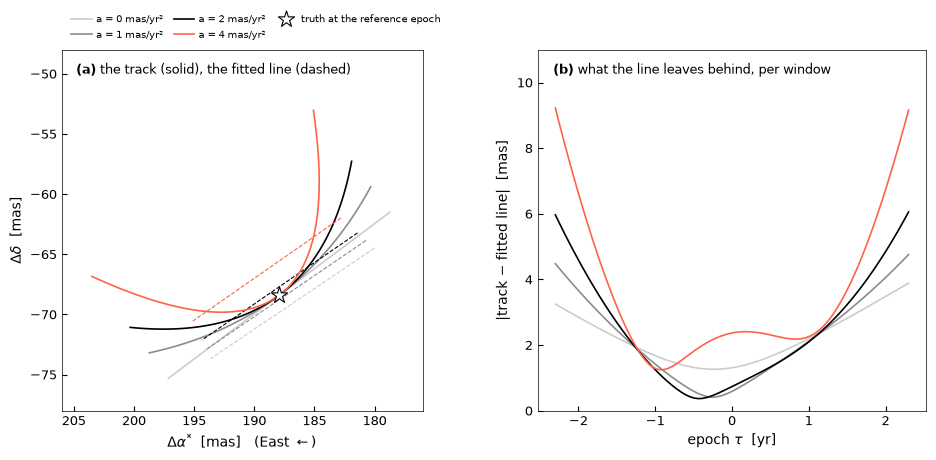

In [20]:
# Figure 4 and its table: the moving fit of an accelerating companion, for four accelerations. (a) the track and
# the fitted straight line, position plus epoch times proper motion (moving_fit["theta"][:2] is the fitted
# position, [2:] the fitted proper motion); (b) their distance in each window. `order` sorts the windows by
# epoch, so that the curves are drawn in time
print("\nan accelerating companion (mu = 4, -3 mas/yr), the moving fit:")
mu = np.array([4.0, -3.0])                                    # the proper motion (mu_alpha*, mu_delta) [mas/yr]
truth = np.r_[theta, mu]                                      # the four true parameters of the moving fit
span = TAU.max() - TAU.min()                                  # the span of the epochs, T [yr]
order = np.argsort(TAU)
fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.6))
for acc, color in zip((0.0, 1.0, 2.0, 4.0), ("0.8", "0.55", "k", ACCENT)):
    # step 1, the curved track, its noisy windows (a new generator of seed 7 for every acceleration: the same
    # noise), and the moving fit, started 10 mas from the truth with zero proper motion
    curved_track = track_of(mu, acc)
    rng_noise = np.random.default_rng(7)
    wins = windows_of_track(curved_track, rng=rng_noise)
    start_moving = np.r_[theta + [8.0, -6.0], 0.0, 0.0]
    moving_fit = joint.fit_joint(wins, EVEN, start_moving, inst, sigma_noise, tau=TAU)

    # step 2, truth: fit minus truth for the four parameters, and the pulls. a T^2 / 8 is the largest
    # distance of a parabola from the chord between its two ends
    error = moving_fit["theta"] - truth
    pulls = error / moving_fit["sigma_theta"]
    # the numbers as text, joined by commas (short comprehensions: one piece of text per parameter)
    error_text = ", ".join(f"{value:5.2f}" for value in error)
    pulls_text = ", ".join(f"{value:5.1f}" for value in pulls)
    print(f"  a = {acc:.0f} mas/yr², departure a T²/8 = {acc * span ** 2 / 8:4.1f} mas: fit − truth ({error_text}"
          f"), pulls ({pulls_text}), chi2/dof {moving_fit['chi2'] / DOF_MOVING:.3f}")

    # step 3, (a) the track (solid) and the fitted straight line (dashed), both in the order of time; (b) the
    # distance between them in each window [mas]
    axes[0].plot(curved_track[order, 0], curved_track[order, 1], color=color, lw=1.2,
                 label=f"a = {acc:.0f} mas/yr²")
    fitted_position = moving_fit["theta"][:2]
    fitted_motion = moving_fit["theta"][2:]
    line = fitted_position + np.outer(TAU[order], fitted_motion)
    axes[0].plot(line[:, 0], line[:, 1], color=color, ls="--", lw=0.8)
    left_behind = curved_track[order] - line                  # one row (dra*, ddec) per window
    axes[1].plot(TAU[order], np.hypot(left_behind[:, 0], left_behind[:, 1]), color=color, lw=1.2)
axes[0].scatter(*theta, **TRUTH, label="truth at the reference epoch")
axes[0].set(xlabel=EAST, ylabel=NORTH, xlim=(206, 176), ylim=(-78, -48), aspect="equal")
axes[0].legend(loc="lower left", bbox_to_anchor=(0.0, 1.0), ncol=3, columnspacing=1.0, handletextpad=0.4)
letter(axes[0], "a", "the track (solid), the fitted line (dashed)")
axes[1].set(xlabel=r"epoch $\tau$  [yr]", ylabel="|track $-$ fitted line|  [mas]", ylim=(0, 11))
letter(axes[1], "b", "what the line leaves behind, per window")
plt.tight_layout()
plt.show()

In [21]:
# the static fit of a companion whose flux varies: `variable` is one (primary, companion) flux pair per window
print("\na companion whose flux varies by ±30 % with a one-year period, the static fit:")
# step 1, the two sets of fluxes. In `variable` the primary's flux is constant (column 0) and the companion's
# follows a sine of the epoch with a period of one year and an amplitude of 30 % (column 1)
primary_flux = np.full(EVEN.size, flux[0])
companion_flux = flux[1] * (1.0 + 0.3 * np.sin(2 * np.pi * TAU))
variable = np.column_stack([primary_flux, companion_flux])
# the companion does not move: the same (dra*, ddec) in each of the 80 windows
static_track = np.broadcast_to(theta, (EVEN.size, 2))

# step 2, the static fit of each set, started 10 mas from the truth. Each set gets a new generator of seed 9,
# so the two sets of windows have the same noise
for name, case_flux in (("constant flux", flux), ("flux varying by ±30 %", variable)):
    rng_noise = np.random.default_rng(9)
    wins = windows_of_track(static_track, flux=case_flux, rng=rng_noise)
    static_fit = joint.fit_joint(wins, EVEN, theta + [8.0, -6.0], inst, sigma_noise)
    report("  " + name, static_fit, theta, DOF)


a companion whose flux varies by ±30 % with a one-year period, the static fit:
  constant flux                          fit − truth (  0.53,   0.18)   pulls (  0.7,   0.2)   fluxes 998, 202   chi2/dof 0.99
  flux varying by ±30 %                  fit − truth (  0.49,   0.15)   pulls (  0.6,   0.2)   fluxes 998, 202   chi2/dof 1.39


## Summary

| atom | effect in this case | alarm | remedy |
|---|---|---|---|
| inverse Radon transform | the companion spread along its track, peak lowered beyond a FWHM of drift | none | faststack's dynamical channel or the moving fit; not an image's job |
| faststack | the same smear | none | the same |
| map of detections | lines envelope the track; the peak displaced and broadened, a ridge at 30 mas/yr | the width grows; `bp.peak_consistency` drops lines | shift each detection to a common epoch under a trial motion (a pipeline's step) |
| static joint fit | biased by a fraction of a mas per mas/yr, several error bars at 20 mas/yr | χ²/dof grows with μ², 1.8 at 20 mas/yr | the moving fit |
| moving joint fit | an orbit's curvature absorbed into the position, a T²/24, four error bars at 4 mas/yr²; a varying flux leaves the position alone | curvature: none, χ² unchanged; varying flux: χ²/dof 1.4 | a model with the curvature, or an external check; per-window fluxes |

## What this establishes

- The static fit of a mover is biased and χ² says so; the moving fit removes
  both. The images smear a mover and the map's lines no longer meet; neither
  is where a mover is measured.
- The moving fit's model is a straight line at constant speed. Curvature
  below the noise is absorbed into the position at the reference epoch, by
  a T²/24, without a trace in χ²: a confident, biased answer that only a
  model with the curvature, or an external check, can expose.
- A varying flux costs χ², not position.